In [22]:
# Install Ultralytics YOLOv8
!pip install ultralytics
!pip install protobuf==3.20.3

  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.34.1
    Uninstalling protobuf-7.34.1:
      Successfully uninstalled protobuf-7.34.1


In [2]:
# Importing Libraries

from ultralytics import YOLO
import os
import cv2
import matplotlib.pyplot as plt
import yaml
from pathlib import Path
import glob

In [21]:
# Creating Project Directory Structure

# Define base directory
BASE_DIR = Path("cctv_car_motorbike_detection")  

# Create directories
for split in ["train", "val", "test"]:
    (BASE_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (BASE_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

print("Directory structure created successfully!")

Directory structure created successfully!


In [22]:
# Creating the Dataset Configuration File (YAML)

data_yaml = {
    'path': str(BASE_DIR),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {
        0: 'cars',  
        1: 'motorbike'
    }
}

with open(BASE_DIR / 'data.yaml', 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print("data.yaml created successfully!")

data.yaml created successfully!


In [23]:
# Loading the nano version for faster training - (Fewer layers, Fewer parameters)

model = YOLO('yolov8n.pt')

# Display model information
model.info()  # Shows (No. of layers, Parameters, Gradients, GFLOPs)

YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8575488)

In [24]:
# Train (Fine-Tune) the Model

results = model.train(
    data=str(BASE_DIR / 'data.yaml'),
    epochs=50,
    imgsz=640,
    batch=8,
    patience=15, # Stops training if no improvement for 15 epochs
    name='car_motorbike_detection'
)

New https://pypi.org/project/ultralytics/8.4.39 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.37 🚀 Python-3.13.9 torch-2.11.0 CPU (Apple M2)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=cctv_car_motorbike_detection/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=car_motorbike_

In [25]:
# Validating the Model

metrics = model.val()

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.37 🚀 Python-3.13.9 torch-2.11.0 CPU (Apple M2)
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.2 ms, read: 221.3±101.5 MB/s, size: 58.9 KB)
val: Scanning /Users/allenlyimo/Desktop/MASTERS NM-AIST/MSc DS:AI/COURSE WORK/SEMISTER 1/AMCS 6203 - ML Theories and Aplication/ASSIGNMENTS/Object Detection/cctv_car_motorbike_detection/labels/val.cache... 153 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 153/153 6.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.5s/it 35.0s.1ss
                   all        153       1276      0.857      0.796      0.854      0.464
                  cars         88       1151      0.824      0.775      0.843        0.4
             motorbike         86        125       0.89      0.816      0.865      0.528
Speed: 0.9ms preprocess, 219.1ms inference, 0.0ms loss, 1.0ms postprocess per image
Results

In [26]:
# Run inference on test images

results = model.predict(
    source=str(BASE_DIR / 'images/test'),
    conf=0.25,
    save=True
)

print("Inference completed. Results saved in the runs/detect directory.")


image 1/154 /Users/allenlyimo/Desktop/MASTERS NM-AIST/MSc DS:AI/COURSE WORK/SEMISTER 1/AMCS 6203 - ML Theories and Aplication/ASSIGNMENTS/Object Detection/cctv_car_motorbike_detection/images/test/-2AE9E484-CD7E-45FB-BD22-3EB7588C1224-png_jpg.rf.DGM3YX8p1EEhBAE1Ewvq.jpg: 640x640 1 cars, 116.3ms
image 2/154 /Users/allenlyimo/Desktop/MASTERS NM-AIST/MSc DS:AI/COURSE WORK/SEMISTER 1/AMCS 6203 - ML Theories and Aplication/ASSIGNMENTS/Object Detection/cctv_car_motorbike_detection/images/test/-2B47E118-DAA1-44C0-814B-34C8CEB3DFE8-png_jpg.rf.BqDQdsjPPxNOO7TTg8l5.jpg: 640x640 1 cars, 77.5ms
image 3/154 /Users/allenlyimo/Desktop/MASTERS NM-AIST/MSc DS:AI/COURSE WORK/SEMISTER 1/AMCS 6203 - ML Theories and Aplication/ASSIGNMENTS/Object Detection/cctv_car_motorbike_detection/images/test/-2F92DBBF-5AC6-4C38-97E9-75A711FCA923-png_jpg.rf.9Hz3WTwlUmkzh8HoPFKk.jpg: 640x640 1 cars, 74.6ms
image 4/154 /Users/allenlyimo/Desktop/MASTERS NM-AIST/MSc DS:AI/COURSE WORK/SEMISTER 1/AMCS 6203 - ML Theories and A

In [15]:
%matplotlib inline

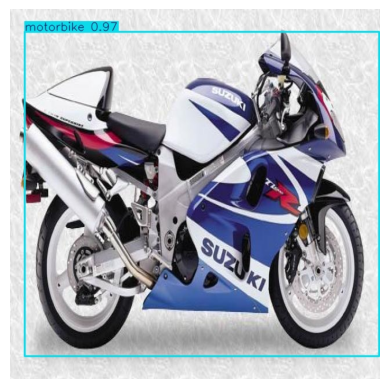

In [27]:
# Display one predicted image

predicted_images = glob.glob('runs/detect/predict/*.jpg')

if predicted_images:
    img = cv2.imread(predicted_images[152])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.imshow(img)
    plt.axis('off')
    plt.show()
else:
    print("No predicted images found.")

In [28]:
# Export to ONNX format
model.export(format='onnx')

Ultralytics 8.4.37 🚀 Python-3.13.9 torch-2.11.0 CPU (Apple M2)

PyTorch: starting from '/Users/allenlyimo/Desktop/MASTERS NM-AIST/MSc DS:AI/COURSE WORK/SEMISTER 1/AMCS 6203 - ML Theories and Aplication/ASSIGNMENTS/Object Detection/runs/detect/car_motorbike_detection3/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (6.0 MB)

ONNX: starting export with onnx 1.21.0 opset 20...
ONNX: slimming with onnxslim 0.1.91...
ONNX: export success ✅ 1.2s, saved as '/Users/allenlyimo/Desktop/MASTERS NM-AIST/MSc DS:AI/COURSE WORK/SEMISTER 1/AMCS 6203 - ML Theories and Aplication/ASSIGNMENTS/Object Detection/runs/detect/car_motorbike_detection3/weights/best.onnx' (11.7 MB)

Export complete (1.3s)
Results saved to /Users/allenlyimo/Desktop/MASTERS NM-AIST/MSc DS:AI/COURSE WORK/SEMISTER 1/AMCS 6203 - ML Theories and Aplication/ASSIGNMENTS/Object Detection/runs/detect/car_motorbike_detection3/weights
Predict:         yolo predict task=detect model=/Users/allenlyimo/

'/Users/allenlyimo/Desktop/MASTERS NM-AIST/MSc DS:AI/COURSE WORK/SEMISTER 1/AMCS 6203 - ML Theories and Aplication/ASSIGNMENTS/Object Detection/runs/detect/car_motorbike_detection3/weights/best.onnx'